PART A: NESTED CROSS-VALIDATION OF FEATURE SELECTION METHODS (2026 PROTOCOL)
[N-terminal Window Tuning] K=20 residues -> 5-Fold MCC = 0.8716
[N-terminal Window Tuning] K=25 residues -> 5-Fold MCC = 0.8788
[N-terminal Window Tuning] K=30 residues -> 5-Fold MCC = 0.8847
--> Selected Optimal N-terminal Composition Window: K = 30 residues

All features (Baseline)    | k=35     | ACC=0.9779±0.0014 | MCC=0.8847±0.0072 | Time=1.0s
Var+Corr Filter            | k=34     | ACC=0.9775±0.0015 | MCC=0.8833±0.0077 | Time=1.0s
Mutual Information         | k=30-35  | ACC=0.9764±0.0018 | MCC=0.8774±0.0089 | Time=77.6s
RFE (Wrapper)              | k=20-30  | ACC=0.9770±0.0017 | MCC=0.8800±0.0091 | Time=25.5s
L1 LogReg (Embedded)       | k=20-30  | ACC=0.9777±0.0018 | MCC=0.8837±0.0092 | Time=42.2s
RF Gini Importance         | k=30-35  | ACC=0.9775±0.0013 | MCC=0.8828±0.0066 | Time=54.2s


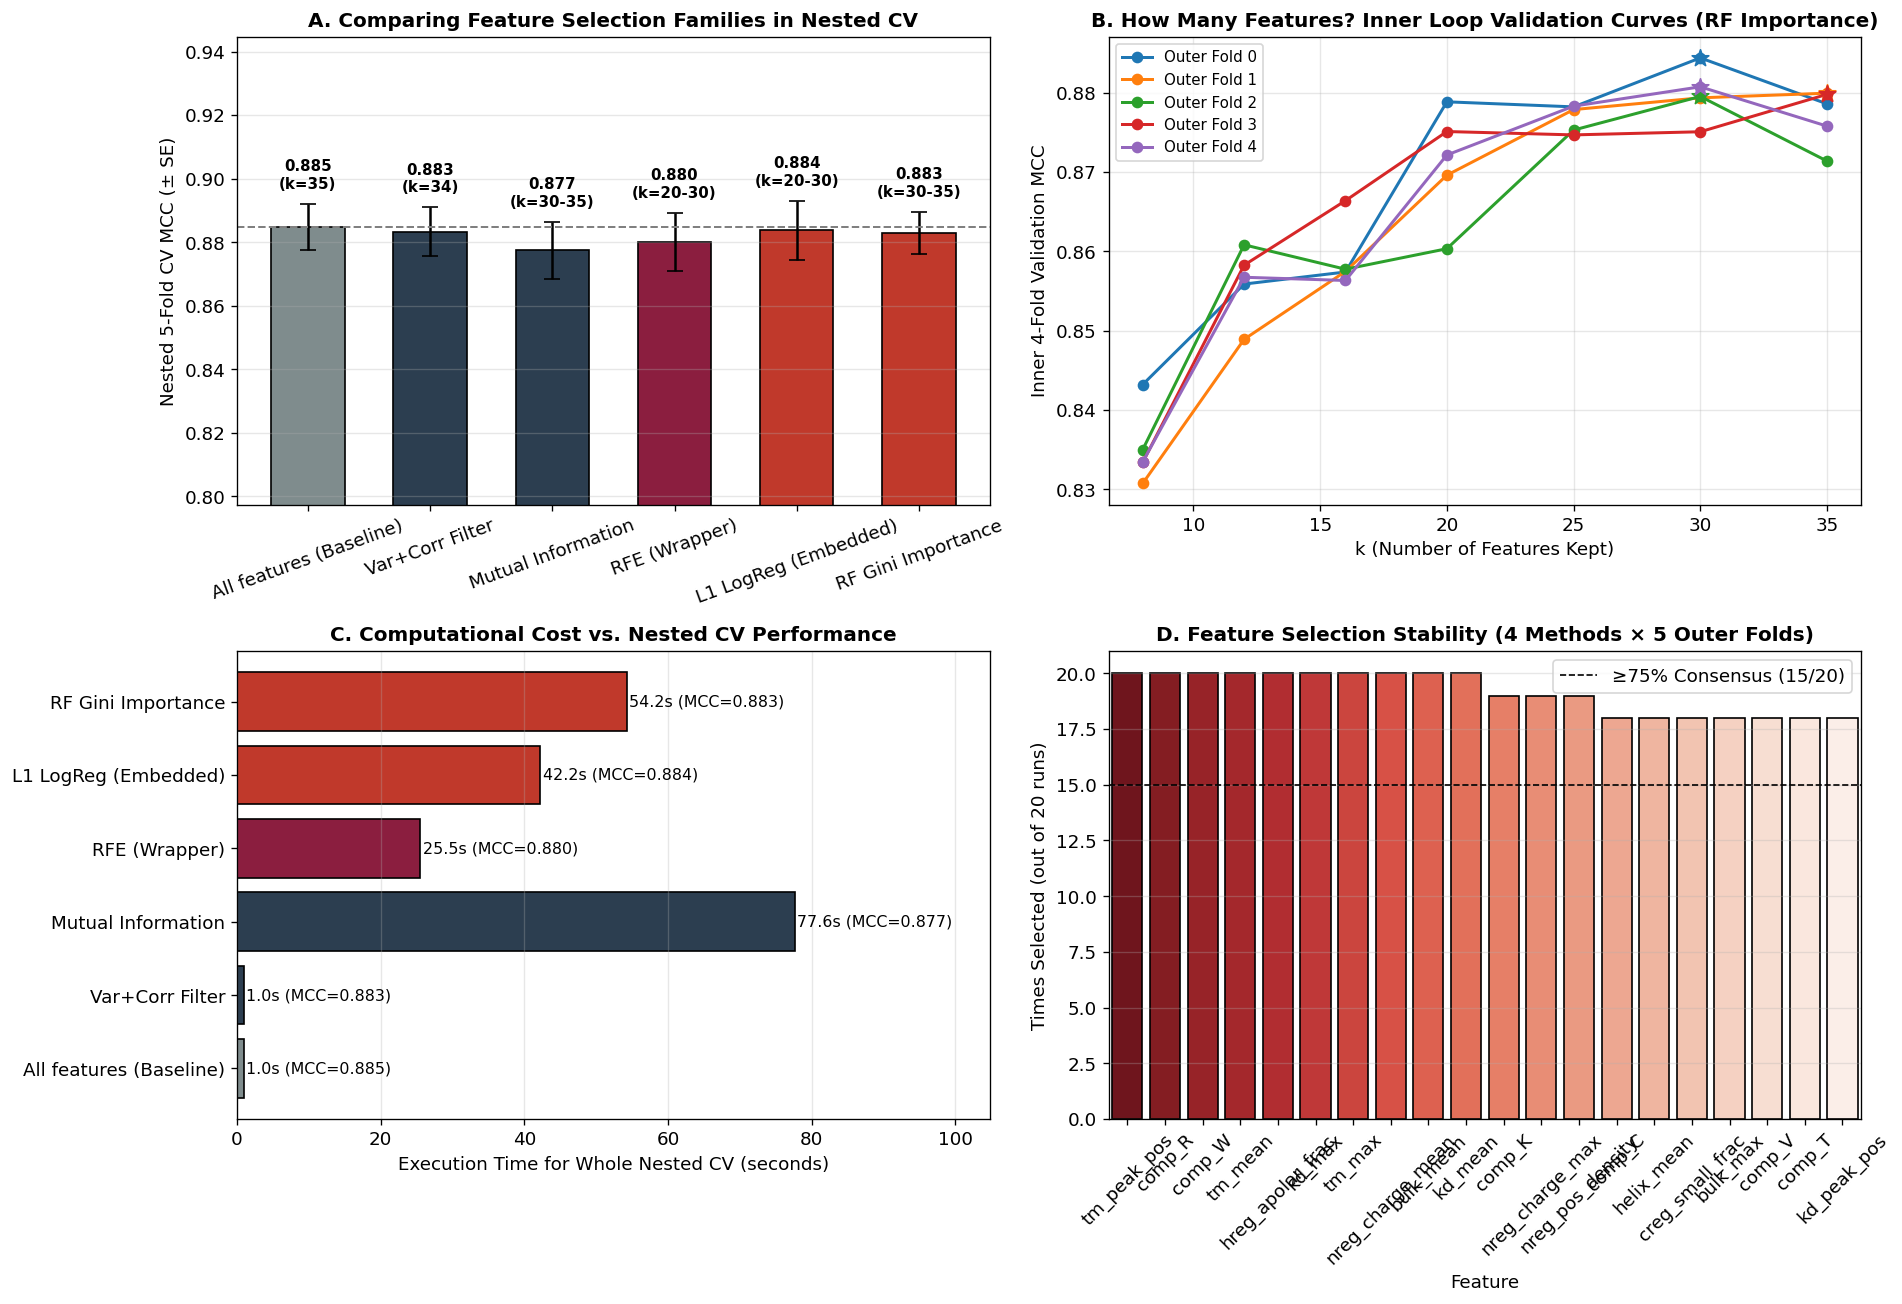


PART B: 5-FOLD CV HYPERPARAMETER TUNING & FINAL PRODUCTION SVM TRAINING
Best Hyperparameters (5-Fold CV): {'selector__k': 30, 'svm__C': 5.0, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Best 5-Fold CV MCC              : 0.8858

--- Final SVM 5-Fold Cross-Validation Summary (Mean ± SE) ---
ACC       : 0.9780 ± 0.0013
Sen       : 0.8943 ± 0.0039
PPV       : 0.9020 ± 0.0106
F1        : 0.8980 ± 0.0056
MCC       : 0.8858 ± 0.0063
ROC_AUC   : 0.9894 ± 0.0012
PR_AUC    : 0.9428 ± 0.0054

--- Hold-Out Benchmarking Set Performance (Final Production SVM) ---
ACC       : 0.9735
PPV       : 0.9029
Sen       : 0.8455
F1        : 0.8732
MCC       : 0.8590
ROC_AUC   : 0.9906
PR_AUC    : 0.9454

PART C: SVM ERROR ANALYSIS & FALSE NEGATIVE DIAGNOSTICS (SLIDES 4-7)
[SVM FP Analysis] Total Benchmark False Positives (FP)  : 20
[SVM FP Analysis] FPs with N-term TM helix (first 90 aa): 13/20 (65.00%)
[SVM FP Analysis] TNs with N-term TM helix (first 90 aa): 183/1797 (10.18%)
[SVM FP Analysis] Fisher's Exact 

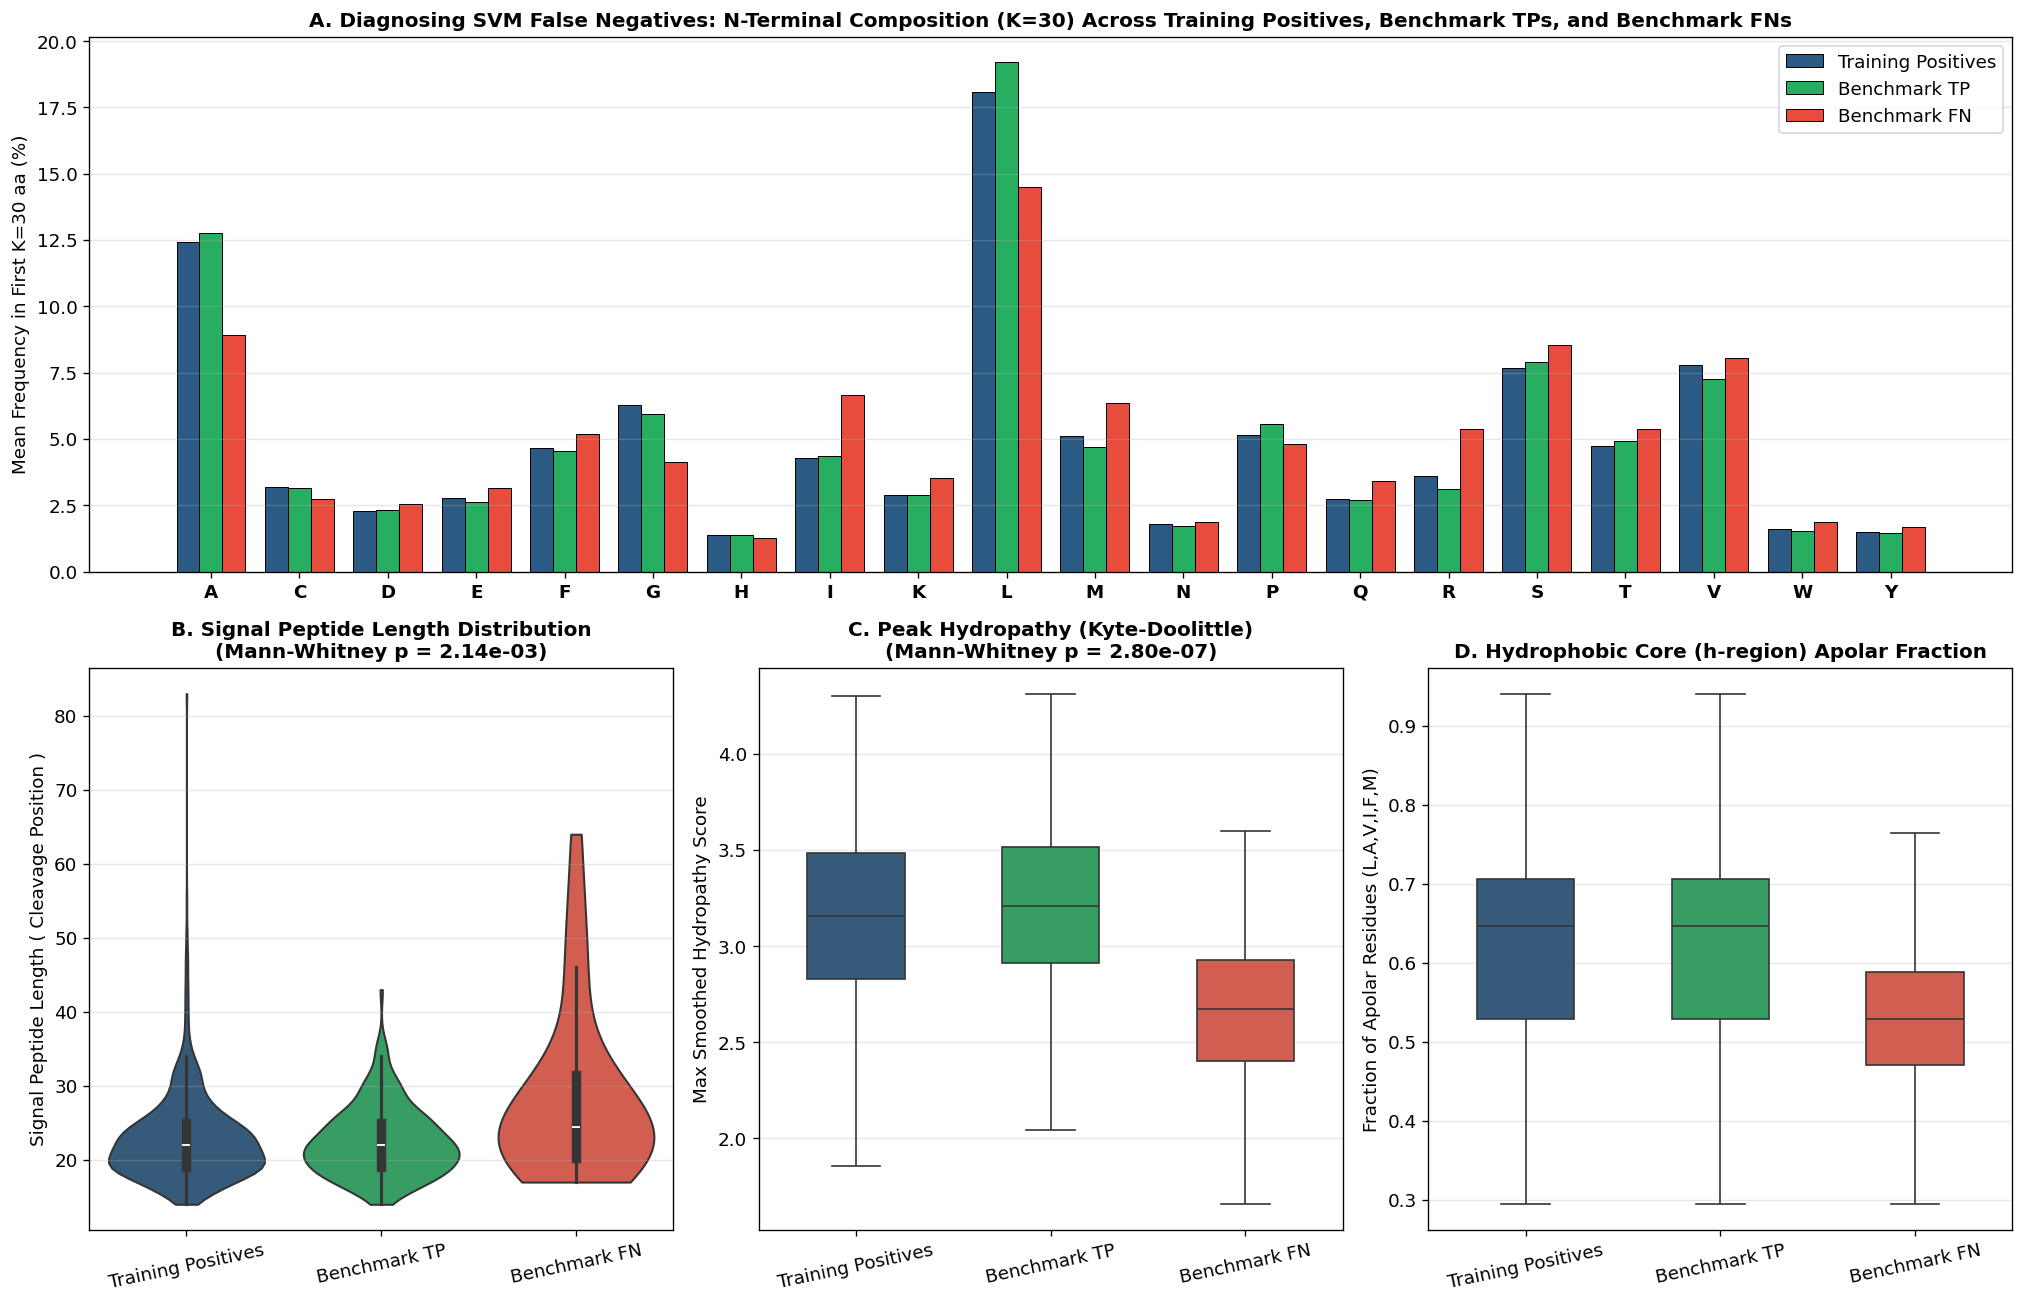

[SUCCESS] Step 5 completed. All Nested CV, SVM benchmark & FN diagnostics saved.


In [1]:
# ==============================================================================
# STEP 5: FEATURE EXTRACTION, NESTED CV SELECTION, SVM & ERROR DIAGNOSIS (2026)
# ==============================================================================
import os
import time
import json
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from Bio import SeqIO
from scipy.stats import mannwhitneyu, fisher_exact
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, mutual_info_classif, RFE, SelectFromModel
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_curve, auc, average_precision_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11
})
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# ------------------------------------------------------------------------------
# 1. LOAD DATASETS (Compatible with Step 4 outputs)
# ------------------------------------------------------------------------------
def find_file(filename):
    search_dirs = [
        ".", "..", "../1- Data_Collection", "../2- Data_Preparation",
        os.path.expanduser("~/LB2_Project"), os.path.expanduser("~")
    ]
    for d in search_dirs:
        candidate = os.path.join(d, filename)
        if os.path.exists(candidate):
            return candidate
        matches = glob.glob(os.path.join(d, "**", filename), recursive=True)
        if matches:
            return matches[0]
    raise FileNotFoundError(f"Could not find {filename}")

train_path = find_file("train.tsv")
bench_path = find_file("benchmark.tsv")
pos_fa_path = find_file("positive.fasta")
neg_fa_path = find_file("negative.fasta")
pos_tsv_path = find_file("positive.tsv")
neg_tsv_path = find_file("negative.tsv")

df_train = pd.read_csv(train_path, sep="\t")
df_bench = pd.read_csv(bench_path, sep="\t")
df_pos_raw = pd.read_csv(pos_tsv_path, sep="\t")
df_neg_raw = pd.read_csv(neg_tsv_path, sep="\t")

pos_seqs = {rec.id.split("|")[1] if "|" in rec.id else rec.id.split()[0]: str(rec.seq).upper()
            for rec in SeqIO.parse(pos_fa_path, "fasta")}
neg_seqs = {rec.id.split("|")[1] if "|" in rec.id else rec.id.split()[0]: str(rec.seq).upper()
            for rec in SeqIO.parse(neg_fa_path, "fasta")}
all_seqs = {**pos_seqs, **neg_seqs}

if "SP cleavage" not in df_train.columns:
    df_train = df_train.merge(df_pos_raw[["Accession", "SP cleavage"]], on="Accession", how="left")
    df_bench = df_bench.merge(df_pos_raw[["Accession", "SP cleavage"]], on="Accession", how="left")
if "N-term transmembrane" not in df_train.columns:
    df_train = df_train.merge(df_neg_raw[["Accession", "N-term transmembrane"]], on="Accession", how="left")
    df_bench = df_bench.merge(df_neg_raw[["Accession", "N-term transmembrane"]], on="Accession", how="left")

df_train["sequence"] = df_train["Accession"].map(all_seqs)
df_bench["sequence"] = df_bench["Accession"].map(all_seqs)

# ------------------------------------------------------------------------------
# 2. PHYSICOCHEMICAL SCALES & FEATURE EXTRACTION (AAindex / ExPASy ProtScale)
# ------------------------------------------------------------------------------
AA_ORDER = list("ACDEFGHIKLMNPQRSTVWY")

# 1. Kyte & Doolittle Hydropathy Scale
KD_SCALE = {
    'A': 1.8, 'R':-4.5, 'N':-3.5, 'D':-3.5, 'C': 2.5, 'Q':-3.5, 'E':-3.5, 'G':-0.4,
    'H':-3.2, 'I': 4.5, 'L': 3.8, 'K':-3.9, 'M': 1.9, 'F': 2.8, 'P':-1.6, 'S':-0.8,
    'T':-0.7, 'W':-0.9, 'Y':-1.3, 'V': 4.2
}
# 2. Net Charge at pH 7.0
CHARGE_SCALE = {
    'A': 0.0, 'R': 1.0, 'N': 0.0, 'D':-1.0, 'C': 0.0, 'Q': 0.0, 'E':-1.0, 'G': 0.0,
    'H': 0.1, 'I': 0.0, 'L': 0.0, 'K': 1.0, 'M': 0.0, 'F': 0.0, 'P': 0.0, 'S': 0.0,
    'T': 0.0, 'W': 0.0, 'Y': 0.0, 'V': 0.0
}
# 3. Zimmerman Bulkiness / Volume Scale
BULK_SCALE = {
    'A':11.50, 'R':14.28, 'N':12.82, 'D':11.68, 'C':13.46, 'Q':14.45, 'E':13.57, 'G': 3.40,
    'H':13.69, 'I':21.40, 'L':21.40, 'K':15.71, 'M':16.25, 'F':19.80, 'P':17.43, 'S': 9.47,
    'T':15.77, 'W':21.67, 'Y':18.03, 'V':21.57
}
# 4. Chou & Fasman Alpha-Helix Propensity
HELIX_SCALE = {
    'A':1.42, 'R':0.98, 'N':0.67, 'D':1.01, 'C':0.70, 'Q':1.11, 'E':1.51, 'G':0.57,
    'H':1.00, 'I':1.08, 'L':1.21, 'K':1.16, 'M':1.45, 'F':1.13, 'P':0.57, 'S':0.77,
    'T':0.83, 'W':1.08, 'Y':0.69, 'V':1.06
}
# 5. Zhao & London Transmembrane Tendency
TM_SCALE = {
    'A': 0.38, 'R':-2.57, 'N':-1.62, 'D':-3.27, 'C':-0.30, 'Q':-1.84, 'E':-2.90, 'G':-0.19,
    'H':-1.44, 'I': 1.97, 'L': 1.82, 'K':-3.46, 'M': 1.40, 'F': 1.98, 'P':-1.44, 'S':-0.53,
    'T':-0.32, 'W': 1.53, 'Y': 0.49, 'V': 1.46
}

def sliding_window_stats(seq, scale_dict, nterm_len=40, win_size=7):
    sub = seq[:nterm_len]
    vals = np.array([scale_dict.get(aa, 0.0) for aa in sub], dtype=np.float64)
    if len(vals) < win_size:
        return float(np.mean(vals)), float(np.max(vals)), float(np.argmax(vals)) / max(len(vals), 1)
    kernel = np.ones(win_size) / win_size
    smoothed = np.convolve(vals, kernel, mode="valid")
    return float(np.mean(smoothed)), float(np.max(smoothed)), float(np.argmax(smoothed)) / len(smoothed)

def build_feature_dataframe(df, k_comp=25, phys_len=40, win_size=7):
    records = []
    for _, row in df.iterrows():
        seq = str(row["sequence"])
        nterm_k = seq[:k_comp]
        L_k = max(len(nterm_k), 1)

        # 1. N-terminal Amino-Acid Composition (20 features)
        feat = {f"comp_{aa}": nterm_k.count(aa) / L_k for aa in AA_ORDER}

        # 2. Physicochemical Sliding-Window Aggregations (12 features)
        kd_mean, kd_max, kd_peak_pos     = sliding_window_stats(seq, KD_SCALE, phys_len, win_size)
        ch_mean, ch_max, _               = sliding_window_stats(seq, CHARGE_SCALE, 15, 5)  # n-region charge
        bk_mean, bk_max, _               = sliding_window_stats(seq, BULK_SCALE, phys_len, win_size)
        hx_mean, hx_max, _               = sliding_window_stats(seq, HELIX_SCALE, phys_len, win_size)
        tm_mean, tm_max, tm_peak_pos     = sliding_window_stats(seq, TM_SCALE, phys_len, 9)

        # Positive-charge & Apolar fractions in n-region (first 10 aa) and h-core (aa 6..22)
        n_reg = seq[:10]
        h_reg = seq[5:22] if len(seq) > 5 else seq
        pos_charge_nreg = sum(n_reg.count(c) for c in "KR") / max(len(n_reg), 1)
        apolar_hreg     = sum(h_reg.count(c) for c in "LAVIFM") / max(len(h_reg), 1)
        small_creg      = sum(seq[12:30].count(c) for c in "AGST") / max(len(seq[12:30]), 1)

        feat.update({
            "kd_mean": kd_mean, "kd_max": kd_max, "kd_peak_pos": kd_peak_pos,
            "nreg_charge_mean": ch_mean, "nreg_charge_max": ch_max, "nreg_pos_density": pos_charge_nreg,
            "bulk_mean": bk_mean, "bulk_max": bk_max,
            "helix_mean": hx_mean, "helix_max": hx_max,
            "tm_mean": tm_mean, "tm_max": tm_max, "tm_peak_pos": tm_peak_pos,
            "hreg_apolar_frac": apolar_hreg, "creg_small_frac": small_creg
        })
        records.append(feat)

    feat_df = pd.DataFrame(records)
    return feat_df

# Custom Variance + Correlation Filter (Slide 40 & 50 of 04-FeatureExtractionSelection)
class VarianceCorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, var_thresh=1e-5, corr_thresh=0.90):
        self.var_thresh = var_thresh
        self.corr_thresh = corr_thresh

    def fit(self, X, y=None):
        X_arr = np.asarray(X)
        variances = np.var(X_arr, axis=0)
        keep_var = np.where(variances > self.var_thresh)[0]
        X_var = X_arr[:, keep_var]

        corr_matrix = np.abs(np.corrcoef(X_var, rowvar=False))
        drop_corr = set()
        n_f = corr_matrix.shape[0]
        for i in range(n_f):
            if i in drop_corr:
                continue
            for j in range(i + 1, n_f):
                if corr_matrix[i, j] > self.corr_thresh:
                    drop_corr.add(j)
        keep_local = [i for i in range(n_f) if i not in drop_corr]
        self.selected_indices_ = keep_var[keep_local]
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.selected_indices_]

# Custom Top-K Selector from Embedded Importance (Random Forest or L1)
class TopKImportanceSelector(BaseEstimator, TransformerMixin):
    def __init__(self, estimator, k=15):
        self.estimator = estimator
        self.k = k

    def fit(self, X, y):
        est = self.estimator.fit(X, y)
        if hasattr(est, "feature_importances_"):
            scores = est.feature_importances_
        else:
            scores = np.abs(est.coef_).ravel()
        self.top_indices_ = np.argsort(scores)[::-1][:self.k]
        self.scores_ = scores
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.top_indices_]

# ------------------------------------------------------------------------------
# 3. PART A: 2026 NESTED CROSS-VALIDATION ACROSS FEATURE SELECTION FAMILIES
#    (5 Outer Folds = Pre-assigned CV folds 0..4; 4 Inner Folds choose k)
# ------------------------------------------------------------------------------
print("=" * 75)
print("PART A: NESTED CROSS-VALIDATION OF FEATURE SELECTION METHODS (2026 PROTOCOL)")
print("=" * 75)

# First, tune optimal N-terminal window K for AA composition on training folds
k_window_candidates = [20, 25, 30]
best_k_window = 25
best_k_mcc = -1.0

for k_win in k_window_candidates:
    X_tmp = build_feature_dataframe(df_train, k_comp=k_win).values
    y_tmp = df_train["label"].values
    folds_tmp = df_train["fold"].values
    mccs = []
    for f_id in range(5):
        trn_m, val_m = (folds_tmp != f_id), (folds_tmp == f_id)
        pipe_tmp = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42))
        ])
        pipe_tmp.fit(X_tmp[trn_m], y_tmp[trn_m])
        mccs.append(matthews_corrcoef(y_tmp[val_m], pipe_tmp.predict(X_tmp[val_m])))
    mean_m = np.mean(mccs)
    print(f"[N-terminal Window Tuning] K={k_win} residues -> 5-Fold MCC = {mean_m:.4f}")
    if mean_m > best_k_mcc:
        best_k_mcc = mean_m
        best_k_window = k_win

print(f"--> Selected Optimal N-terminal Composition Window: K = {best_k_window} residues\n")

# Extract full 35-feature matrices using selected K
train_feat_df = build_feature_dataframe(df_train, k_comp=best_k_window)
bench_feat_df = build_feature_dataframe(df_bench, k_comp=best_k_window)
FEATURE_NAMES = list(train_feat_df.columns)
N_TOTAL_FEATURES = len(FEATURE_NAMES)

X_train_all = train_feat_df.values
y_train_all = df_train["label"].values
outer_folds = df_train["fold"].values

X_bench_all = bench_feat_df.values
y_bench_all = df_bench["label"].values

K_CANDIDATES = [8, 12, 16, 20, 25, 30, N_TOTAL_FEATURES]

selection_methods = {
    "All features (Baseline)": ("baseline", None),
    "Var+Corr Filter": ("filter", VarianceCorrelationFilter(corr_thresh=0.90)),
    "Mutual Information": ("filter", "mi"),
    "RFE (Wrapper)": ("wrapper", "rfe"),
    "L1 LogReg (Embedded)": ("embedded", "l1"),
    "RF Gini Importance": ("embedded", "rf")
}

nested_cv_results = []
selection_frequency = {f: 0 for f in FEATURE_NAMES}  # Track across 4 methods x 5 outer folds = 20 runs
rf_inner_curves = {}  # Store inner validation curves per outer fold for Slide 53 plot

for method_name, (family, sel_type) in selection_methods.items():
    t0 = time.time()
    outer_accs, outer_mccs, outer_f1s, chosen_ks = [], [], [], []

    for out_f in range(5):
        trn_mask = (outer_folds != out_f)
        tst_mask = (outer_folds == out_f)
        X_trn, y_trn, f_trn = X_train_all[trn_mask], y_train_all[trn_mask], outer_folds[trn_mask]
        X_tst, y_tst = X_train_all[tst_mask], y_train_all[tst_mask]

        if sel_type is None:
            best_k = N_TOTAL_FEATURES
            pipe_final = Pipeline([
                ("scaler", StandardScaler()),
                ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42))
            ])
            pipe_final.fit(X_trn, y_trn)
            y_pred = pipe_final.predict(X_tst)

        elif isinstance(sel_type, VarianceCorrelationFilter):
            pipe_final = Pipeline([
                ("scaler", StandardScaler()),
                ("sel", VarianceCorrelationFilter(corr_thresh=0.90)),
                ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42))
            ])
            pipe_final.fit(X_trn, y_trn)
            best_k = len(pipe_final.named_steps["sel"].selected_indices_)
            y_pred = pipe_final.predict(X_tst)

        else:
            # Inner 4-fold loop on the 4 training folds to choose k
            unique_inner_folds = np.unique(f_trn)
            k_mean_scores = []
            k_se_scores   = []

            for k_cand in K_CANDIDATES:
                inner_scores = []
                for in_f in unique_inner_folds:
                    in_trn = (f_trn != in_f)
                    in_val = (f_trn == in_f)
                    scaler = StandardScaler()
                    X_in_trn = scaler.fit_transform(X_trn[in_trn])
                    X_in_val = scaler.transform(X_trn[in_val])

                    if sel_type == "mi":
                        selector = SelectKBest(
                            lambda X, y: mutual_info_classif(X, y, random_state=42), k=k_cand
                        )
                    elif sel_type == "rfe":
                        selector = RFE(
                            LogisticRegression(max_iter=500, random_state=42),
                            n_features_to_select=k_cand, step=2
                        )
                    elif sel_type == "l1":
                        selector = TopKImportanceSelector(
                            LogisticRegression(penalty="l1", solver="liblinear", C=0.5, random_state=42),
                            k=k_cand
                        )
                    elif sel_type == "rf":
                        selector = TopKImportanceSelector(
                            RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
                            k=k_cand
                        )

                    X_in_trn_sel = selector.fit_transform(X_in_trn, y_trn[in_trn])
                    X_in_val_sel = selector.transform(X_in_val)

                    clf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
                    clf.fit(X_in_trn_sel, y_trn[in_trn])
                    inner_scores.append(matthews_corrcoef(y_trn[in_val], clf.predict(X_in_val_sel)))

                k_mean_scores.append(np.mean(inner_scores))
                k_se_scores.append(np.std(inner_scores, ddof=1) / np.sqrt(len(unique_inner_folds)))

            if sel_type == "rf":
                rf_inner_curves[out_f] = (K_CANDIDATES, k_mean_scores, k_se_scores)

            # Pick best k (within 1-SE rule / peak accuracy, Slide 53-54)
            best_idx = int(np.argmax(k_mean_scores))
            best_k   = K_CANDIDATES[best_idx]

            # Refit on all 4 training folds with chosen best_k
            scaler_out = StandardScaler()
            X_trn_sc = scaler_out.fit_transform(X_trn)
            X_tst_sc = scaler_out.transform(X_tst)

            if sel_type == "mi":
                sel_out = SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=42), k=best_k)
                sel_out.fit(X_trn_sc, y_trn)
                sel_indices = sel_out.get_support(indices=True)
            elif sel_type == "rfe":
                sel_out = RFE(LogisticRegression(max_iter=500, random_state=42),
                              n_features_to_select=best_k, step=2)
                sel_out.fit(X_trn_sc, y_trn)
                sel_indices = sel_out.get_support(indices=True)
            elif sel_type == "l1":
                sel_out = TopKImportanceSelector(
                    LogisticRegression(penalty="l1", solver="liblinear", C=0.5, random_state=42), k=best_k
                )
                sel_out.fit(X_trn_sc, y_trn)
                sel_indices = sel_out.top_indices_
            elif sel_type == "rf":
                sel_out = TopKImportanceSelector(
                    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), k=best_k
                )
                sel_out.fit(X_trn_sc, y_trn)
                sel_indices = sel_out.top_indices_

            for idx in sel_indices:
                selection_frequency[FEATURE_NAMES[idx]] += 1

            clf_out = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
            clf_out.fit(X_trn_sc[:, sel_indices], y_trn)
            y_pred = clf_out.predict(X_tst_sc[:, sel_indices])

        chosen_ks.append(best_k)
        outer_accs.append(accuracy_score(y_tst, y_pred))
        outer_mccs.append(matthews_corrcoef(y_tst, y_pred))
        outer_f1s.append(f1_score(y_tst, y_pred))

    elapsed = time.time() - t0
    nested_cv_results.append({
        "Method": method_name,
        "Family": family,
        "k_range": f"{min(chosen_ks)}-{max(chosen_ks)}" if min(chosen_ks) != max(chosen_ks) else f"{chosen_ks[0]}",
        "ACC_mean": np.mean(outer_accs), "ACC_se": np.std(outer_accs, ddof=1)/np.sqrt(5),
        "MCC_mean": np.mean(outer_mccs), "MCC_se": np.std(outer_mccs, ddof=1)/np.sqrt(5),
        "F1_mean":  np.mean(outer_f1s),  "F1_se":  np.std(outer_f1s, ddof=1)/np.sqrt(5),
        "Time_s": elapsed
    })
    print(f"{method_name:26s} | k={nested_cv_results[-1]['k_range']:6s} | "
          f"ACC={np.mean(outer_accs):.4f}±{np.std(outer_accs, ddof=1)/np.sqrt(5):.4f} | "
          f"MCC={np.mean(outer_mccs):.4f}±{np.std(outer_mccs, ddof=1)/np.sqrt(5):.4f} | "
          f"Time={elapsed:.1f}s")

df_nested_summary = pd.DataFrame(nested_cv_results)

# Plot Nested CV Diagnostics (Matching 2026 Lecture 04 Slides 50, 53, 56, 57)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel A: Nested CV MCC Comparison by Family (Slide 50)
family_colors = {"baseline": "#7F8C8D", "filter": "#2C3E50", "wrapper": "#8B1E3F", "embedded": "#C0392B"}
bar_cols = [family_colors[f] for f in df_nested_summary["Family"]]
bars_a = axes[0, 0].bar(
    df_nested_summary["Method"], df_nested_summary["MCC_mean"],
    yerr=df_nested_summary["MCC_se"], capsize=5, color=bar_cols, edgecolor="black", width=0.6
)
axes[0, 0].axhline(df_nested_summary["MCC_mean"].iloc[0], color="gray", linestyle="--", lw=1.2)
for b, row in zip(bars_a, df_nested_summary.itertuples()):
    axes[0, 0].text(b.get_x() + b.get_width()/2, row.MCC_mean + row.MCC_se + 0.005,
                    f"{row.MCC_mean:.3f}\n(k={row.k_range})", ha="center", fontsize=9, fontweight="bold")
axes[0, 0].set_ylim(max(0.5, df_nested_summary["MCC_mean"].min() - 0.08),
                    min(1.0, df_nested_summary["MCC_mean"].max() + 0.06))
axes[0, 0].set_ylabel("Nested 5-Fold CV MCC (± SE)")
axes[0, 0].set_title("A. Comparing Feature Selection Families in Nested CV", fontweight="bold")
axes[0, 0].tick_params(axis="x", rotation=20)
axes[0, 0].grid(axis="y", alpha=0.3)

# Panel B: Inner Validation Curve vs k across Outer Folds (Slide 53)
for out_f, (ks, means, _) in rf_inner_curves.items():
    axes[0, 1].plot(ks, means, marker="o", lw=1.8, label=f"Outer Fold {out_f}")
    best_i = int(np.argmax(means))
    axes[0, 1].scatter([ks[best_i]], [means[best_i]], s=110, marker="*", zorder=5)
axes[0, 1].set_xlabel("k (Number of Features Kept)")
axes[0, 1].set_ylabel("Inner 4-Fold Validation MCC")
axes[0, 1].set_title("B. How Many Features? Inner Loop Validation Curves (RF Importance)", fontweight="bold")
axes[0, 1].legend(fontsize=9)
axes[0, 1].grid(alpha=0.3)

# Panel C: Computational Cost vs Nested CV Accuracy/MCC (Slide 56)
axes[1, 0].barh(df_nested_summary["Method"], df_nested_summary["Time_s"], color=bar_cols, edgecolor="black")
for i, row in enumerate(df_nested_summary.itertuples()):
    axes[1, 0].text(row.Time_s + 0.3, i, f"{row.Time_s:.1f}s (MCC={row.MCC_mean:.3f})", va="center", fontsize=9.5)
axes[1, 0].set_xlim(0, df_nested_summary["Time_s"].max() * 1.35)
axes[1, 0].set_xlabel("Execution Time for Whole Nested CV (seconds)")
axes[1, 0].set_title("C. Computational Cost vs. Nested CV Performance", fontweight="bold")
axes[1, 0].grid(axis="x", alpha=0.3)

# Panel D: Feature Selection Stability Across 4 Methods x 5 Outer Folds = 20 Runs (Slide 57)
df_stab = pd.DataFrame({
    "Feature": list(selection_frequency.keys()),
    "Count": list(selection_frequency.values())
}).sort_values("Count", ascending=False).head(20)
sns.barplot(data=df_stab, x="Feature", y="Count", ax=axes[1, 1], palette="Reds_r", edgecolor="black")
axes[1, 1].axhline(15, color="black", linestyle="--", lw=1, label="≥75% Consensus (15/20)")
axes[1, 1].set_ylabel("Times Selected (out of 20 runs)")
axes[1, 1].set_xlabel("Feature")
axes[1, 1].set_title("D. Feature Selection Stability (4 Methods × 5 Outer Folds)", fontweight="bold")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/fig5_1_nested_cv_feature_selection.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# 4. PART B: COMPLETE 5-FOLD CV HYPERPARAMETER TUNING & PRODUCTION SVM
#    (Slide 2 & 3 of 05-Benchmarking: Tune via 5-fold CV -> Retrain on WHOLE
#     training set -> Test ONCE on Benchmarking set)
# ------------------------------------------------------------------------------
print("\n" + "=" * 75)
print("PART B: 5-FOLD CV HYPERPARAMETER TUNING & FINAL PRODUCTION SVM TRAINING")
print("=" * 75)

# Predefined 5-fold CV split from df_train["fold"]
cv_splits = [
    (np.where(outer_folds != f)[0], np.where(outer_folds == f)[0])
    for f in range(5)
]

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", TopKImportanceSelector(
        RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1), k=20
    )),
    ("svm", SVC(probability=True, random_state=42))
])

param_grid = {
    "selector__k": [16, 20, 25, 30, N_TOTAL_FEATURES],
    "svm__kernel": ["rbf", "linear"],
    "svm__C": [0.5, 1.0, 2.0, 5.0],
    "svm__gamma": ["scale", 0.05, 0.01]
}

grid_search = GridSearchCV(
    svm_pipeline, param_grid=param_grid, cv=cv_splits,
    scoring="matthews_corrcoef", n_jobs=-1, refit=True
)
grid_search.fit(X_train_all, y_train_all)

best_params = grid_search.best_params_
print(f"Best Hyperparameters (5-Fold CV): {best_params}")
print(f"Best 5-Fold CV MCC              : {grid_search.best_score_:.4f}")

# Evaluate the best hyperparameter configuration across the 5 CV folds for Mean ± SE reporting
svm_cv_records = []
for f_idx, (trn_idx, tst_idx) in enumerate(cv_splits):
    model_f = grid_search.best_estimator_
    # Clone and fit on fold training split
    from sklearn.base import clone
    clf_f = clone(grid_search.best_estimator_)
    clf_f.fit(X_train_all[trn_idx], y_train_all[trn_idx])
    preds_f = clf_f.predict(X_train_all[tst_idx])
    probs_f = clf_f.predict_proba(X_train_all[tst_idx])[:, 1]
    fpr_f, tpr_f, _ = roc_curve(y_train_all[tst_idx], probs_f)
    svm_cv_records.append({
        "Fold": f_idx,
        "ACC": accuracy_score(y_train_all[tst_idx], preds_f),
        "Sen": recall_score(y_train_all[tst_idx], preds_f),
        "PPV": precision_score(y_train_all[tst_idx], preds_f),
        "F1":  f1_score(y_train_all[tst_idx], preds_f),
        "MCC": matthews_corrcoef(y_train_all[tst_idx], preds_f),
        "ROC_AUC": auc(fpr_f, tpr_f),
        "PR_AUC":  average_precision_score(y_train_all[tst_idx], probs_f)
    })

df_svm_cv = pd.DataFrame(svm_cv_records)
print("\n--- Final SVM 5-Fold Cross-Validation Summary (Mean ± SE) ---")
svm_cv_summary = {}
for m_name in ["ACC", "Sen", "PPV", "F1", "MCC", "ROC_AUC", "PR_AUC"]:
    mv = df_svm_cv[m_name].mean()
    sv = df_svm_cv[m_name].std(ddof=1) / np.sqrt(5)
    svm_cv_summary[m_name] = {"mean": float(mv), "se": float(sv)}
    print(f"{m_name:10s}: {mv:.4f} ± {sv:.4f}")

# Test the retrained production model (grid_search.best_estimator_ is refitted on ALL training data)
final_svm_model = grid_search.best_estimator_
top_k_indices   = final_svm_model.named_steps["selector"].top_indices_
TOP_FEATURES_FINAL = [FEATURE_NAMES[i] for i in top_k_indices]

bench_preds_svm = final_svm_model.predict(X_bench_all)
bench_probs_svm = final_svm_model.predict_proba(X_bench_all)[:, 1]
fpr_s, tpr_s, _ = roc_curve(y_bench_all, bench_probs_svm)

svm_bench_metrics = {
    "ACC": accuracy_score(y_bench_all, bench_preds_svm),
    "PPV": precision_score(y_bench_all, bench_preds_svm),
    "Sen": recall_score(y_bench_all, bench_preds_svm),
    "F1":  f1_score(y_bench_all, bench_preds_svm),
    "MCC": matthews_corrcoef(y_bench_all, bench_preds_svm),
    "ROC_AUC": auc(fpr_s, tpr_s),
    "PR_AUC":  average_precision_score(y_bench_all, bench_probs_svm)
}

print("\n--- Hold-Out Benchmarking Set Performance (Final Production SVM) ---")
for k, v in svm_bench_metrics.items():
    print(f"{k:10s}: {v:.4f}")

# ------------------------------------------------------------------------------
# 5. PART C: 2026 SVM ERROR ANALYSIS & DIAGNOSIS OF FALSE NEGATIVES
#    (Slides 4, 5, 6, 7 of 05-Benchmarking:
#     - Isolate FPs & compute N-term TM helix fraction
#     - Compare Training Positives, Benchmark TPs, and Benchmark FNs across:
#       1. N-terminal AA composition (up to K)
#       2. Signal peptide length distribution
#       3. Other adopted physicochemical features)
# ------------------------------------------------------------------------------
print("\n" + "=" * 75)
print("PART C: SVM ERROR ANALYSIS & FALSE NEGATIVE DIAGNOSTICS (SLIDES 4-7)")
print("=" * 75)

df_bench_svm = df_bench.copy()
df_bench_svm["svm_prob"] = bench_probs_svm
df_bench_svm["svm_pred"] = bench_preds_svm
conditions_s = [
    (df_bench_svm["label"] == 1) & (df_bench_svm["svm_pred"] == 1),
    (df_bench_svm["label"] == 0) & (df_bench_svm["svm_pred"] == 0),
    (df_bench_svm["label"] == 0) & (df_bench_svm["svm_pred"] == 1),
    (df_bench_svm["label"] == 1) & (df_bench_svm["svm_pred"] == 0),
]
df_bench_svm["outcome"] = np.select(conditions_s, ["TP", "TN", "FP", "FN"], default="Other")
df_bench_svm.to_csv("results/svm_benchmark_predictions.tsv", sep="\t", index=False)

# --- 5.1 False Positive Analysis: TM Helices in First 90 Residues ---
bench_neg_s = df_bench_svm[df_bench_svm["label"] == 0].copy()
bench_neg_s["N-term transmembrane"] = bench_neg_s["N-term transmembrane"].astype(bool)

fp_svm_df = bench_neg_s[bench_neg_s["svm_pred"] == 1]
tn_svm_df = bench_neg_s[bench_neg_s["svm_pred"] == 0]

fp_svm_tm_count = int(fp_svm_df["N-term transmembrane"].sum())
fp_svm_total    = len(fp_svm_df)
fp_svm_tm_frac  = (fp_svm_tm_count / fp_svm_total * 100) if fp_svm_total > 0 else 0.0

tn_svm_tm_count = int(tn_svm_df["N-term transmembrane"].sum())
tn_svm_total    = len(tn_svm_df)
tn_svm_tm_frac  = (tn_svm_tm_count / tn_svm_total * 100) if tn_svm_total > 0 else 0.0

odds_svm_tm, p_svm_tm = fisher_exact([
    [fp_svm_tm_count, fp_svm_total - fp_svm_tm_count],
    [tn_svm_tm_count, tn_svm_total - tn_svm_tm_count]
])

print(f"[SVM FP Analysis] Total Benchmark False Positives (FP)  : {fp_svm_total}")
print(f"[SVM FP Analysis] FPs with N-term TM helix (first 90 aa): {fp_svm_tm_count}/{fp_svm_total} ({fp_svm_tm_frac:.2f}%)")
print(f"[SVM FP Analysis] TNs with N-term TM helix (first 90 aa): {tn_svm_tm_count}/{tn_svm_total} ({tn_svm_tm_frac:.2f}%)")
print(f"[SVM FP Analysis] Fisher's Exact Odds Ratio             : {odds_svm_tm:.2f} (p = {p_svm_tm:.2e})")

# Taxonomic distribution of SVM errors
kingdom_svm_stats = []
for k_name, grp in df_bench_svm.groupby("Kingdom"):
    n_pos = (grp["label"] == 1).sum()
    n_neg = (grp["label"] == 0).sum()
    n_fp  = (grp["outcome"] == "FP").sum()
    n_fn  = (grp["outcome"] == "FN").sum()
    kingdom_svm_stats.append({
        "Kingdom": k_name, "Total": len(grp), "FP": n_fp, "FN": n_fn,
        "FPR (%)": (n_fp / n_neg * 100) if n_neg > 0 else 0.0,
        "FNR (%)": (n_fn / n_pos * 100) if n_pos > 0 else 0.0
    })
df_kingdom_svm = pd.DataFrame(kingdom_svm_stats).sort_values("Total", ascending=False)
print("\n[Taxonomic Error Distribution across Kingdoms (SVM)]")
print(df_kingdom_svm.to_string(index=False))

# --- 5.2 Diagnosing SVM False Negatives: Compare 3 Groups (Slide 6 & 7) ---
# Group 1: Training Positives
# Group 2: Benchmark True Positives (TP)
# Group 3: Benchmark False Negatives (FN)
trn_pos_mask  = (df_train["label"] == 1).values
b_tp_mask     = (df_bench_svm["outcome"] == "TP").values
b_fn_mask     = (df_bench_svm["outcome"] == "FN").values

df_g1 = train_feat_df[trn_pos_mask].copy()
df_g1["SP_length"] = df_train.loc[trn_pos_mask, "SP cleavage"].values
df_g1["Group"] = "Training Positives"

df_g2 = bench_feat_df[b_tp_mask].copy()
df_g2["SP_length"] = df_bench_svm.loc[b_tp_mask, "SP cleavage"].values
df_g2["Group"] = "Benchmark TP"

df_g3 = bench_feat_df[b_fn_mask].copy()
df_g3["SP_length"] = df_bench_svm.loc[b_fn_mask, "SP cleavage"].values
df_g3["Group"] = "Benchmark FN"

df_diag = pd.concat([df_g1, df_g2, df_g3], ignore_index=True)

# Statistical comparison of SP Length & Hydrophobicity between Training Positives and Benchmark FN
_, p_splen = mannwhitneyu(df_g1["SP_length"].dropna(), df_g3["SP_length"].dropna())
_, p_kdmax = mannwhitneyu(df_g1["kd_max"].dropna(), df_g3["kd_max"].dropna())
print(f"\n[SVM FN Diagnosis] SP Length Median: Train Pos={df_g1['SP_length'].median():.1f} aa, "
      f"Bench TP={df_g2['SP_length'].median():.1f} aa, Bench FN={df_g3['SP_length'].median():.1f} aa (p={p_splen:.2e})")
print(f"[SVM FN Diagnosis] Max Hydropathy Median: Train Pos={df_g1['kd_max'].median():.2f}, "
      f"Bench TP={df_g2['kd_max'].median():.2f}, Bench FN={df_g3['kd_max'].median():.2f} (p={p_kdmax:.2e})")

# Plot 4-Panel SVM Error Diagnosis Figure (Matching Slide 6 & 7 of 05-Benchmarking)
fig = plt.figure(figsize=(17, 11))
gs  = fig.add_gridspec(2, 3, height_ratios=[1, 1.05])

# Panel A: N-terminal AA Composition (up to selected K) across the 3 groups
ax_comp = fig.add_subplot(gs[0, :])
comp_cols = [f"comp_{aa}" for aa in AA_ORDER]
comp_means = df_diag.groupby("Group")[comp_cols].mean().loc[
    ["Training Positives", "Benchmark TP", "Benchmark FN"]
] * 100.0
x_aa = np.arange(20)
w_aa = 0.26
palette_3 = ["#2B5B84", "#27AE60", "#E74C3C"]
for idx_g, grp_name in enumerate(["Training Positives", "Benchmark TP", "Benchmark FN"]):
    ax_comp.bar(x_aa + (idx_g - 1)*w_aa, comp_means.loc[grp_name].values,
                width=w_aa, label=grp_name, color=palette_3[idx_g], edgecolor="black", linewidth=0.6)
ax_comp.set_xticks(x_aa)
ax_comp.set_xticklabels(AA_ORDER, fontweight="bold")
ax_comp.set_ylabel(f"Mean Frequency in First K={best_k_window} aa (%)")
ax_comp.set_title(f"A. Diagnosing SVM False Negatives: N-Terminal Composition (K={best_k_window}) "
                  f"Across Training Positives, Benchmark TPs, and Benchmark FNs", fontweight="bold")
ax_comp.legend()
ax_comp.grid(axis="y", alpha=0.3)

# Panel B: Signal Peptide Length Distribution across the 3 groups
ax_len = fig.add_subplot(gs[1, 0])
sns.violinplot(
    data=df_diag, x="Group", y="SP_length", ax=ax_len,
    palette=palette_3, inner="box", cut=0
)
ax_len.set_title(f"B. Signal Peptide Length Distribution\n(Mann-Whitney p = {p_splen:.2e})", fontweight="bold")
ax_len.set_ylabel("Signal Peptide Length ( Cleavage Position )")
ax_len.set_xlabel("")
ax_len.tick_params(axis="x", rotation=12)
ax_len.grid(axis="y", alpha=0.3)

# Panel C: Peak Hydrophobicity (kd_max) & H-region Apolarity across the 3 groups
ax_phys1 = fig.add_subplot(gs[1, 1])
sns.boxplot(
    data=df_diag, x="Group", y="kd_max", ax=ax_phys1,
    palette=palette_3, width=0.5, showfliers=False
)
ax_phys1.set_title(f"C. Peak Hydropathy (Kyte-Doolittle)\n(Mann-Whitney p = {p_kdmax:.2e})", fontweight="bold")
ax_phys1.set_ylabel("Max Smoothed Hydropathy Score")
ax_phys1.set_xlabel("")
ax_phys1.tick_params(axis="x", rotation=12)
ax_phys1.grid(axis="y", alpha=0.3)

# Panel D: Other Adopted Physicochemical Features (TM Tendency & Helix Propensity)
ax_phys2 = fig.add_subplot(gs[1, 2])
sns.boxplot(
    data=df_diag, x="Group", y="hreg_apolar_frac", ax=ax_phys2,
    palette=palette_3, width=0.5, showfliers=False
)
ax_phys2.set_title("D. Hydrophobic Core (h-region) Apolar Fraction", fontweight="bold")
ax_phys2.set_ylabel("Fraction of Apolar Residues (L,A,V,I,F,M)")
ax_phys2.set_xlabel("")
ax_phys2.tick_params(axis="x", rotation=12)
ax_phys2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/fig5_2_svm_error_diagnosis.png", bbox_inches="tight")
plt.show()

# Save SVM results JSON for Step 6 Master Comparison
with open("results/svm_summary.json", "w") as f:
    json.dump({
        "best_k_window": int(best_k_window),
        "best_params": {k: (int(v) if isinstance(v, (np.integer,)) else v) for k, v in best_params.items()},
        "selected_features": TOP_FEATURES_FINAL,
        "cv_summary": svm_cv_summary,
        "benchmark_metrics": {k: float(v) for k, v in svm_bench_metrics.items()},
        "error_analysis": {
            "fp_total": fp_svm_total,
            "fp_tm_count": fp_svm_tm_count,
            "fp_tm_percent": float(fp_svm_tm_frac),
            "tn_tm_percent": float(tn_svm_tm_frac),
            "tm_odds_ratio": float(odds_svm_tm),
            "tm_fisher_p": float(p_svm_tm),
            "fn_total": int(b_fn_mask.sum()),
            "sp_len_median_train_pos": float(df_g1["SP_length"].median()),
            "sp_len_median_bench_tp": float(df_g2["SP_length"].median()),
            "sp_len_median_bench_fn": float(df_g3["SP_length"].median()),
            "sp_len_p_val": float(p_splen)
        }
    }, f, indent=2)
print("[SUCCESS] Step 5 completed. All Nested CV, SVM benchmark & FN diagnostics saved.")